# Fixed-width window FFD + Z — all assets

Setting from `README.md` §3 and `ffd-d-sweep.ipynb`:

| Item | Setting |
|---|---|
| Method | Fixed-width window FFD on `log(close)`, daily |
| τ / d / window | 1e-4 / 0.25 / 445 bars |
| Train / test | 2021-01-01 → 2023-12-31 / 2024-01-01 → |
| Z anchor | each asset's first FFD value (warm-up end, README §3) |
| Z reference | **Expanding** (not fixed, not rolling): fixed start = anchor, end moves forward with each bar. See below |
| Plot range | data start → **2022-12-31** (`PLOT_END`). FFD and Z are causal, so cutting later data does not change any value shown |
| Z rolling (4th panel) | **Rolling 445 bars (= FFD window)**: μ_t, σ_t from the last 445 FFD bars up to t. Same anchor and burn-in. Equals expanding until the window fills (red dotted line): crypto 2021-06-07, QQQ 2022-07-13, XAUUSD 2022-06-10 |
| Z burn-in | Z left empty for the first `Z_MIN` FFD bars after the anchor (σ is unstable on a few points) |

### Z reference = expanding (read this before reading the Z plots)

`Z_t = (FFD_t − μ_t) / σ_t`, where μ_t and σ_t use **every FFD value from the anchor up to and including bar t** (ddof = 0).

| Reference type | μ/σ window on day t | Used here? |
|---|---|---|
| Fixed (train-only) | 2021-01-01 → 2023-12-31, the same for every day | No |
| **Expanding** | anchor → t (start fixed, end moves forward) | **Yes** |
| Rolling | t − N years → t (both ends move) | No |

| Asset | Anchor (first FFD value) | First Z (after `Z_MIN` = 60 FFD bars) |
|---|---|---|
| BTC / ETH | 2020-03-20 | 2020-05-18 |
| QQQ | 2020-10-06 | 2020-12-30 |
| XAUUSD | 2020-09-21 | 2020-12-11 |

What this means when reading the plots:
- **Causal.** Z_t uses no data after t, so cutting the series at `PLOT_END` does not change any Z value.
- **Early Z is noisy.** In 2020–21 μ/σ rest on a few months of data (mostly a rally for BTC/ETH), so Z can reach ±4 there (e.g. BTC early 2021).
- **The anchor period counts forever.** Old data (2020) never leaves μ/σ, so after a lasting level shift Z re-centres only slowly.
- The Z of about +6 seen for XAUUSD in 2024–26 elsewhere in the discussion came from a **fixed** 2021–23 reference, not from this notebook.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('../../data')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
TAU, D = 1e-4, 0.25
TRAIN = ('2021-01-01', '2023-12-31')
Z_MIN = 60   # bars of FFD before Z is reported
PLOT_END = '2022-12-31'

def ffd_weights(d, tau=TAU):
    w = [1.0]
    while True:
        k = len(w)
        nxt = -w[-1] * (d - k + 1) / k
        if abs(nxt) < tau:
            return np.asarray(w)
        w.append(nxt)

def ffd(log_close, d=D, tau=TAU):
    w = ffd_weights(d, tau)
    y = np.full(len(log_close), np.nan)
    y[len(w) - 1:] = np.convolve(log_close.values, w, mode='valid')
    return pd.Series(y, index=log_close.index)

def load(sym):
    df = pd.read_parquet(DATA / sym / f'{sym}-sorted-1d.parquet')
    ts = pd.to_datetime(df['timestamp'])
    ts = ts.dt.tz_convert(None) if ts.dt.tz is not None else ts
    assert ts.is_monotonic_increasing and ts.is_unique
    return df.set_axis(ts)['close']

W = len(ffd_weights(D)); W

445

In [2]:
frames, anchors = {}, {}
for s in ASSETS:
    close = load(s).loc[:PLOT_END]
    f = ffd(np.log(close))
    anchor = f.first_valid_index()                  # warm-up end
    fa = f.loc[anchor:]
    mu = fa.expanding(min_periods=Z_MIN).mean()
    sd = fa.expanding(min_periods=Z_MIN).std(ddof=0)
    r = fa.rolling(W, min_periods=Z_MIN)            # rolling over the FFD window (445 bars)
    frames[s] = pd.DataFrame({'close': close, 'ffd': f, 'z': (fa - mu) / sd,
                              'z_roll': (fa - r.mean()) / r.std(ddof=0)})
    anchors[s] = anchor

pd.DataFrame({s: {'Z anchor (first FFD)': anchors[s].date(),
                  'first Z': frames[s].z.first_valid_index().date(),
                  f'rolling {W} full from': frames[s].ffd.loc[anchors[s]:].index[W - 1].date()
                      if frames[s].ffd.loc[anchors[s]:].size >= W else 'not in range',
                  'last bar': frames[s].index[-1].date()} for s in ASSETS}).T

,Z anchor (first FFD),first Z,rolling 445 full from,last bar
BTC,2020-03-20,2020-05-18,2021-06-07,2022-12-31
ETH,2020-03-20,2020-05-18,2021-06-07,2022-12-31
QQQ,2020-10-06,2020-12-30,2022-07-13,2022-12-30
XAUUSD,2020-09-21,2020-12-11,2022-06-10,2022-12-30


## Price / FFD / Z

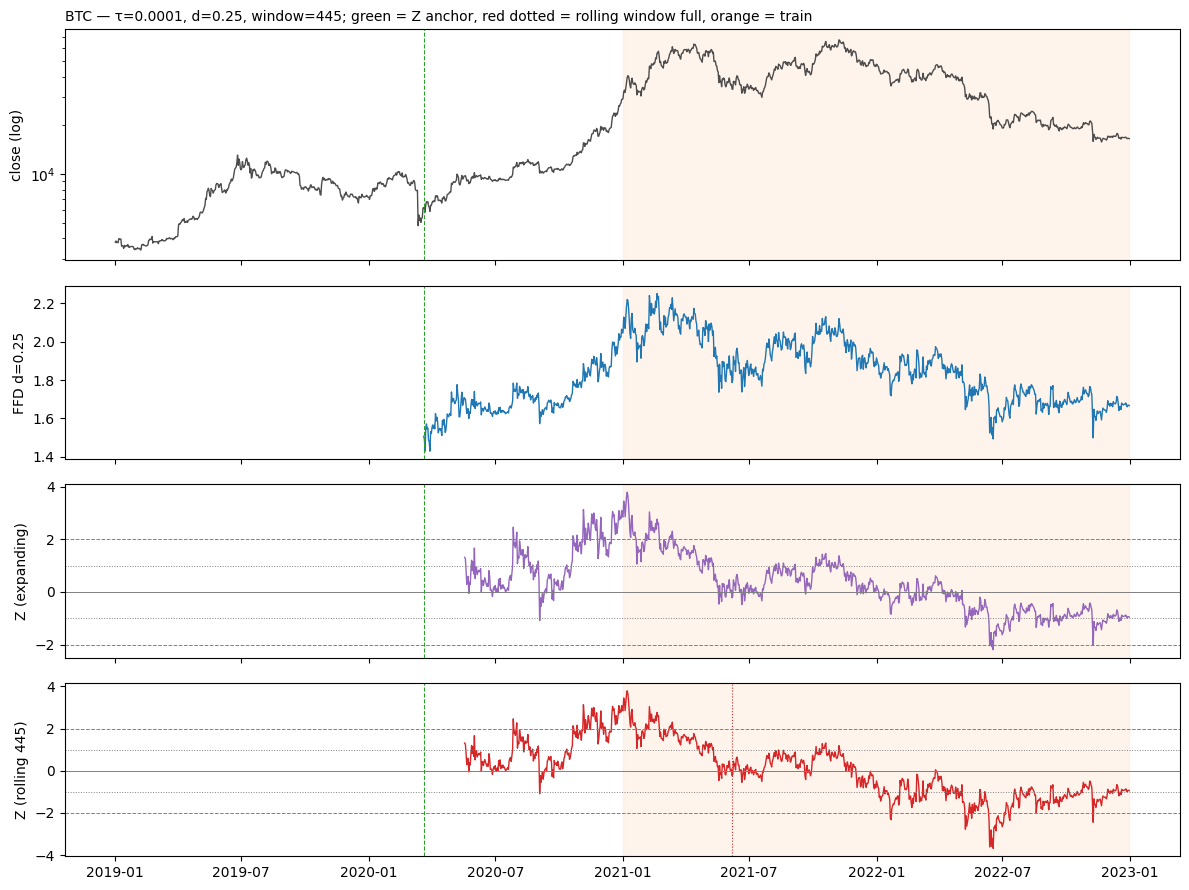

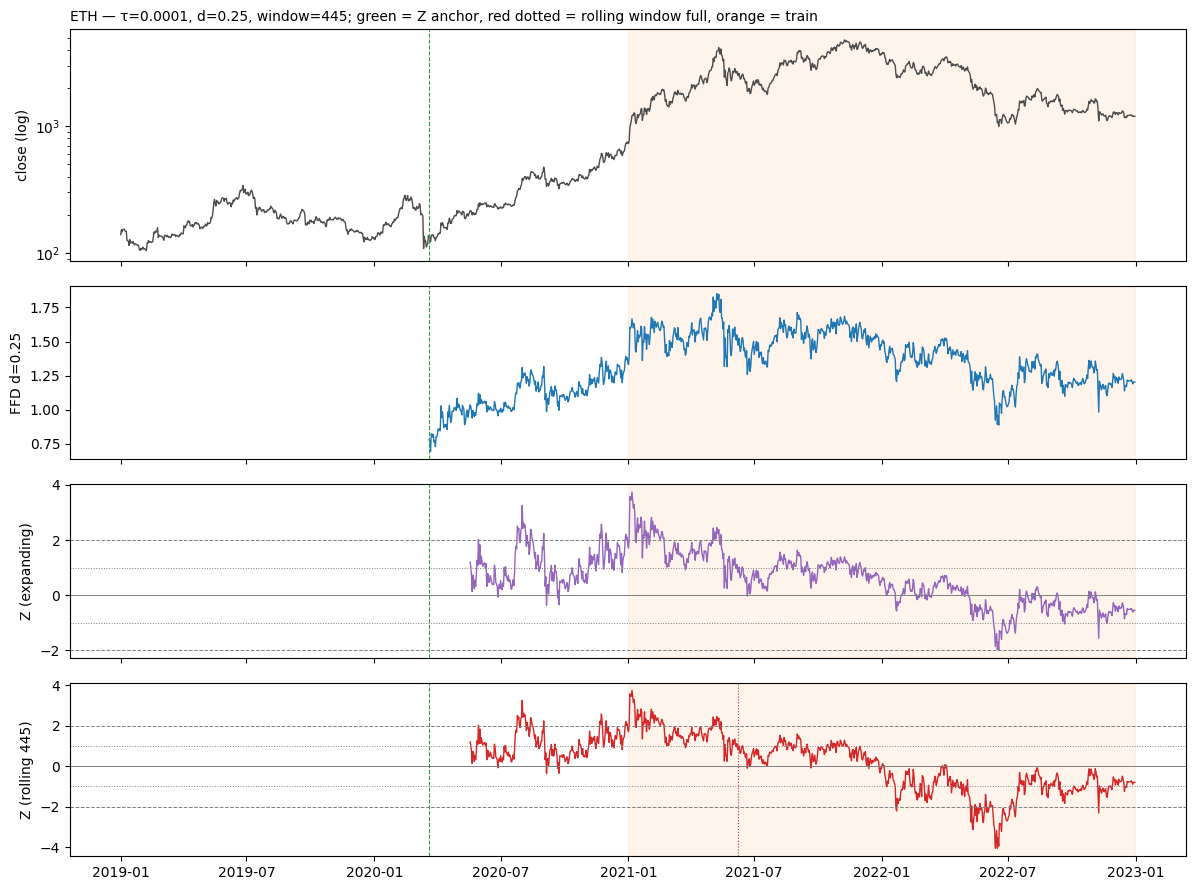

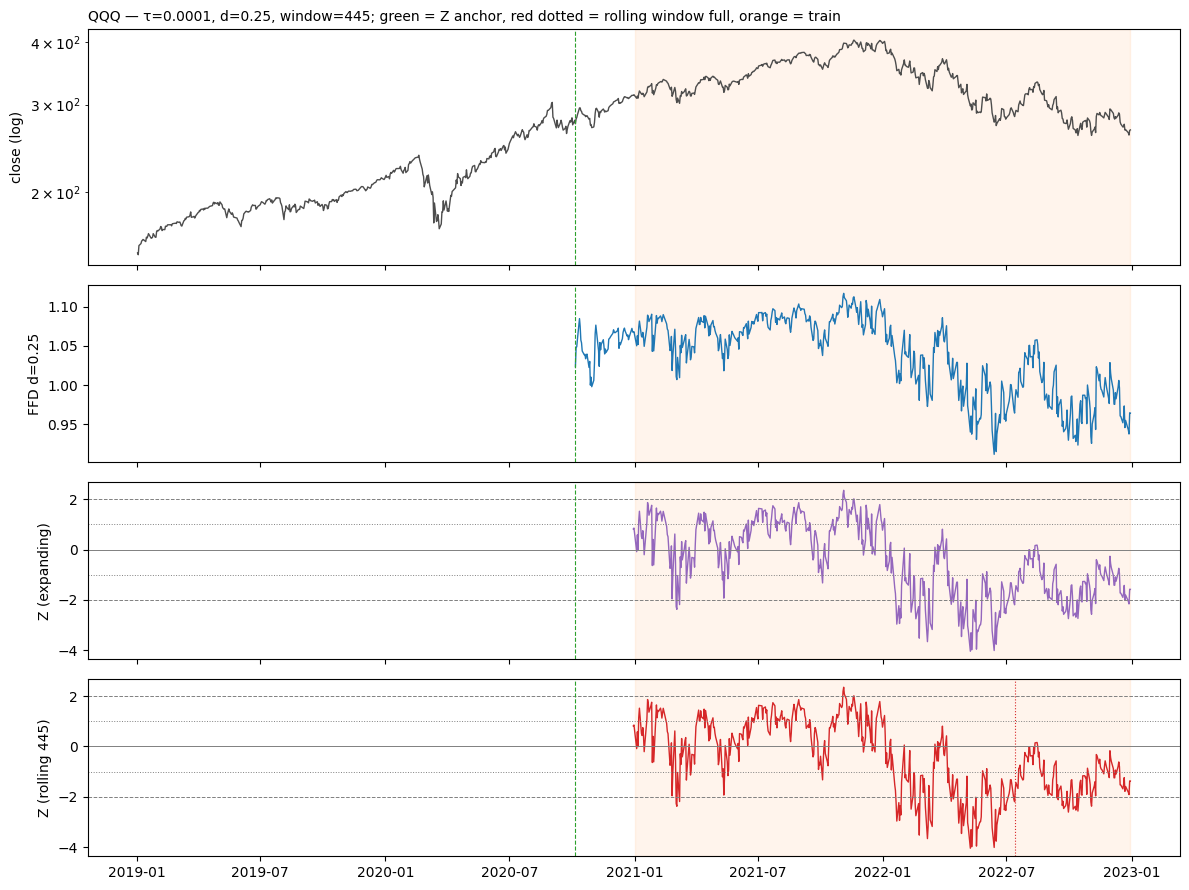

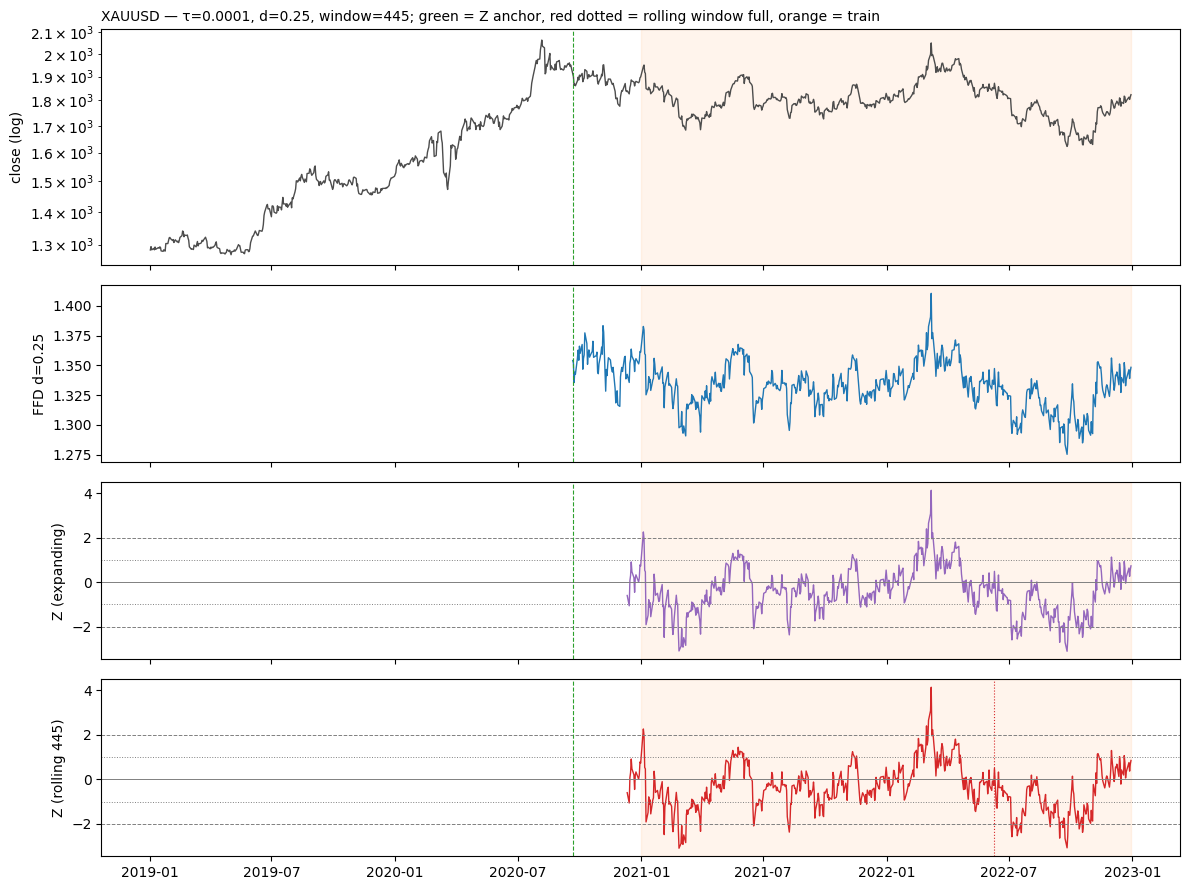

In [3]:
for s in ASSETS:
    df = frames[s]
    fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True,
                           gridspec_kw={'height_ratios': [2, 1.5, 1.5, 1.5]})
    ax[0].plot(df.index, df.close, color='0.3', lw=1); ax[0].set_yscale('log'); ax[0].set_ylabel('close (log)')
    ax[1].plot(df.index, df.ffd, color='tab:blue', lw=1); ax[1].set_ylabel(f'FFD d={D}')
    ax[2].plot(df.index, df.z, color='tab:purple', lw=1); ax[2].set_ylabel('Z (expanding)')
    ax[3].plot(df.index, df.z_roll, color='tab:red', lw=1); ax[3].set_ylabel(f'Z (rolling {W})')
    fa = df.ffd.loc[anchors[s]:]
    if fa.size >= W:
        ax[3].axvline(fa.index[W - 1], color='tab:red', lw=0.8, ls=':')   # rolling window full
    for a in ax[2:]:
        for lvl, ls in [(0, '-'), (1, ':'), (-1, ':'), (2, '--'), (-2, '--')]:
            a.axhline(lvl, color='0.5', lw=0.7, ls=ls)
    for a in ax:
        a.axvspan(pd.Timestamp(TRAIN[0]), min(pd.Timestamp(TRAIN[1]), df.index[-1]), color='tab:orange', alpha=0.08)
        a.axvline(anchors[s], color='tab:green', lw=0.8, ls='--')
    ax[0].set_title(f'{s} — τ={TAU:g}, d={D}, window={W}; green = Z anchor, red dotted = rolling window full, orange = train', loc='left', fontsize=10)
    plt.tight_layout(); plt.show()

## Z summary by year

In [4]:
agg = dict(mean='mean', std='std', pct_abs_gt2=lambda z: (z.dropna().abs() > 2).mean() * 100)
summary = pd.concat({s: pd.concat({'expanding': frames[s].z.groupby(frames[s].index.year).agg(**agg),
                                   f'rolling {W}': frames[s].z_roll.groupby(frames[s].index.year).agg(**agg)}, axis=1)
                     for s in ASSETS})
summary.dropna(how='all').round(2)

expanding                   rolling 445                  
                      mean   std pct_abs_gt2        mean   std pct_abs_gt2
       timestamp                                                          
BTC    2020           1.11  0.93       20.61        1.11  0.93       20.61
       2021           0.98  0.82       11.51        0.83  0.93       11.51
       2022          -0.63  0.53        1.10       -1.27  0.58        9.59
ETH    2020           1.08  0.67       10.96        1.08  0.67       10.96
       2021           1.28  0.66       15.07        1.18  0.74       15.07
       2022          -0.29  0.52        0.00       -1.18  0.75       14.52
QQQ    2020           0.83  0.02        0.00        0.83  0.02        0.00
       2021           0.63  0.89        2.78        0.63  0.89        2.78
       2022          -1.58  0.99       33.47       -1.53  0.99       29.88
XAUUSD 2020           0.15  0.55        0.00        0.15  0.55        0.00
       2021          -0.49  0.90        5.81       -0.49  0.90        5.81
       2022          -0.32  1.20       10.85       -0.27  1.19        8.91

Notes
- The Z reference is causal and anchored at the warm-up end, so 2020 bars count toward μ/σ but carry no test-period information.
- Stationarity ≠ mean reversion of price. Z alone is not a buy/sell signal (README §4).
- An expanding reference adapts slowly. A level shift can keep Z on one side for a long time.

## Maintenance rule — when to re-check ADF, τ, d and Z (decided 2026-10-31, d rule revised 2026-11-01)

| What | When | Action |
|---|---|---|
| **ADF** | Every year, on the last 1 year and the last 2–3 years; also track FFD mean/σ | **Warning label / regime sign only.** A failure, even a persistent one, does not change d. It marks a trend regime in which Z does not revert to its centre. |
| **τ** | Only if the setup changes: bar timeframe, new asset with a short history, FFD method | Otherwise keep τ = 1e-4. τ was never tuned to market behaviour. |
| **d** | **Keep d = 0.25.** No re-selection triggered by ADF failure (removed 2026-11-01) | Re-selecting d for a structural change is possible later, but "structural change" is not defined yet. If d ever changes: re-select on past data only, start a new Z anchor, retrain; old and new Z are not comparable. |
| **Z reference** | ADF passes but Z sits off-centre for long stretches | Fix the reference (e.g. rolling Z). Keep d. |

- An ADF failure changes nothing about d. Why: gold failed through the 2024–25 rally and passed again in 2025–26 Q3 with d unchanged (`ffd-z-plot3.ipynb`). Raising d at end-2024 (0.30) and end-2025 (≈ 0.40) would have chased a trend that then ended (`ffd-z-plot-xau03.ipynb`).
- During a failure, don't read Z as a mean-reversion signal.
- Removed 2026-11-01: "raise d on persistent ADF failure (2–3-year window fails, or two years in a row)". See `../reports/r1-fracdiff-adf-failure.md`.
- Set this rule before looking further at 2024+, so the response isn't tuned to the test period.